# Part 8 — Gratings vs. Natural Scenes

Asks whether the transient peak in cross-mouse representational consistency
is a general property of V1 stimulus processing or is specific to natural
images. Static grating conditions (orientation x spatial frequency) serve as
the comparison: if gratings produce a flatter temporal profile and a lower
peak in raw consistency, the natural-scene result reflects something
specific about the representational content of naturalistic stimuli rather
than a generic response gain modulation.

**Depends on:** `responses.h5` (static-gratings tensors, VISp),
               `noise_ceiling_gratings_VISp.npy`,
               `part3_outputs.npz` (natural-scenes reference curves),
               `manifest.json`
**Outputs saved:** none (terminal notebook)

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path(".").resolve()))
from utils import (
    setup_archive,
    window_response,
    compute_similarity_matrices,
    per_image_consistency,
    cluster_bootstrap_ci,
    image_matched_sliding_curve,
    apply_plot_style,
    ts_ratio,
    print_figure_data,
    subpopulation_consistency,
    mean_pair_consistency,
)

import json
import gc
from itertools import combinations
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy.stats import spearmanr

SEED = 42

plt.rcParams.update({
    'font.family': 'sans-serif', 'font.size': 11,
    'axes.labelsize': 12, 'axes.titlesize': 12,
    'xtick.labelsize': 10, 'ytick.labelsize': 10,
    'legend.fontsize': 9.5, 'figure.dpi': 150,
})
sns.set_style('ticks')

colors   = apply_plot_style()
COL_DATA = colors["COL_DATA"]   # natural scenes
COL_GR   = colors["COL_GR"]     # gratings
COL_FIT  = colors["COL_FIT"]    # peak annotations / statistics
COL_REF  = colors["COL_REF"]    # reference lines / baselines
COL_SUB  = colors["COL_TEST"]   # natural scenes, item-count-matched subsampling control

In [2]:
# Load archive, extract if needed, resolve output paths.
manifest, bin_edges, ARCHIVE_DIR, FIGURES_DIR, OUTPUTS_DIR = setup_archive(
    zip_path    = '../preprocessed_data.zip',
    archive_dir = '../preprocessed_data',
    figures_dir = '../figures',
    outputs_dir = '.',
)
SESSION_IDS      = manifest['selected_session_ids_visp']
N_CONDITIONS     = manifest['n_grating_conditions']     # 30
N_IMAGES         = manifest['n_images']                 # 118

nc_gratings  = np.load(ARCHIVE_DIR / 'noise_ceiling_gratings_VISp.npy')
mean_nc_gr   = nc_gratings.mean(0)       # (30,)
scalar_nc_gr = mean_nc_gr.mean()         # scalar
print(f'Gratings NC: mean = {scalar_nc_gr:.4f}, '
      f'range [{nc_gratings.min():.3f}, {nc_gratings.max():.3f}]')

p3 = np.load(OUTPUTS_DIR / 'part3_outputs.npz')
times_ms_ns        = p3['times_ms']
mean_c_ns          = p3['mean_c']
window_centers_ms  = p3['window_centers_ms'].tolist()
WINDOW_WIDTH_MS    = float(p3['window_width_ms'])
peak_t_ns          = float(p3['peak_t'])
peak_c_ns          = float(p3['peak_c'])
baseline_ns        = float(p3['baseline'])
sustained_floor_ns = float(p3['sustained_floor'])

p1 = np.load(OUTPUTS_DIR / 'part1_outputs.npz')
mean_nc_ns          = p1['noise_ceiling'].mean()
reliability_ns      = p1['noise_ceiling'].mean(0)   # (118,) per-image, across mice
consistency_ns_full = p1['consistency']             # (118,) fixed 0-250ms window,

SLIDE_START_MS = int(times_ms_ns.min())
SLIDE_END_MS   = int(times_ms_ns.max()) + 1

print(f'Natural scenes: peak = {peak_c_ns:.4f} at {peak_t_ns:.0f} ms, '
      f'mean NC = {mean_nc_ns:.4f}')
print(f'Sliding window: {len(window_centers_ms)} windows, '
      f'width = {WINDOW_WIDTH_MS:.0f} ms')

Archive already extracted: C:\Users\janak\GitHub\cross-mouse-v1-rsa\preprocessed_data
Manifest: 32 VISp sessions | 118 images | 479 bins × 1 ms
Gratings NC: mean = 0.9917, range [0.949, 0.998]
Natural scenes: peak = 0.3065 at 100 ms, mean NC = 0.9778
Sliding window: 43 windows, width = 25 ms


In [3]:
print('Loading static-gratings tensors...')
grating_tensors = {}
with h5py.File(ARCHIVE_DIR / 'responses.h5', 'r') as f:
    for sid in SESSION_IDS:
        grp = f[f'static_gratings/VISp/{sid}']
        grating_tensors[sid] = grp['tensor'][:]   # (30, n_units, 95)
print(f'Loaded {len(grating_tensors)} sessions.')

Loading static-gratings tensors...


Loaded 32 sessions.


In [4]:
print('Loading natural-scenes tensors (for item-count-matched subsampling control)...')
ns_tensors = {}
with h5py.File(ARCHIVE_DIR / 'responses.h5', 'r') as f:
    for sid in SESSION_IDS:
        grp = f[f'natural_scenes/VISp/{sid}']
        ns_tensors[sid] = grp['tensor'][:]   # (118, n_units, 95)
print(f'Loaded {len(ns_tensors)} sessions.')

Loading natural-scenes tensors (for item-count-matched subsampling control)...


Loaded 32 sessions.


## 8.1 — Fixed-window (0–250 ms) consistency for gratings vs. natural scenes

As a baseline comparison, compute the scalar mean consistency in the
0–250 ms window used throughout Parts 1–2 for both stimuli.

In [5]:
def fixed_window_consistency_gr(t_lo=0, t_hi=250):
    mats = [window_response(grating_tensors[sid], t_lo, t_hi)
            for sid in SESSION_IDS]
    sims = compute_similarity_matrices(mats)
    c,_,_ = per_image_consistency(sims)
    return c.mean(), c

c_gr_scalar, c_gr_per_cond = fixed_window_consistency_gr()

c_ns_scalar = consistency_ns_full.mean()

print(f'\nFixed window (0–250 ms):')
print(f'  Natural scenes mean consistency: {c_ns_scalar:.4f}')
print(f'  Gratings mean consistency:       {c_gr_scalar:.4f}')
print(f'  (within-mouse response reliability — gratings: {scalar_nc_gr:.4f}, '
      f'natural scenes: {mean_nc_ns:.4f} — both near-ceiling and comparable, '
      f'so raw consistency is directly comparable between conditions)')


Fixed window (0–250 ms):
  Natural scenes mean consistency: 0.3142
  Gratings mean consistency:       0.7198
  (within-mouse response reliability — gratings: 0.9917, natural scenes: 0.9778 — both near-ceiling and comparable, so raw consistency is directly comparable between conditions)


## 8.1b — Item-count-matched control

The raw-magnitude gap above (0.720 vs. 0.314) is not apples-to-apples: gratings
have 30 conditions (29-dim similarity profiles) while natural scenes have 118
images (117-dim profiles), and `per_image_consistency`'s Spearman correlation
is computed over those profiles — so its noise properties depend on item
count independent of any real representational difference. To control for
this, natural-scenes consistency is recomputed after subsampling the same 30
items per random draw (matching the gratings condition count exactly), both
for the fixed 0–250 ms window and across the full sliding-window profile.

In [6]:
N_DRAWS_SUB = 50

# Fixed 0-250 ms window, subsampled to N_CONDITIONS=30 images per draw
_, sub_fixed_mean, sub_fixed_lo, sub_fixed_hi, _ = image_matched_sliding_curve(
    ns_tensors, target_n=N_CONDITIONS,
    window_centers_ms=[125.0], window_width_ms=250.0,
    n_draws=N_DRAWS_SUB, seed=SEED,
)
c_ns_sub_scalar = sub_fixed_mean[0]
c_ns_sub_lo     = sub_fixed_lo[0]
c_ns_sub_hi     = sub_fixed_hi[0]

print(f'Fixed window (0-250 ms), item-count-matched to 30 items/draw ({N_DRAWS_SUB} draws):')
print(f'  Natural scenes, full 118 images : {c_ns_scalar:.4f}')
print(f'  Natural scenes, 30-image draws  : {c_ns_sub_scalar:.4f}  '
      f'[{c_ns_sub_lo:.4f}, {c_ns_sub_hi:.4f}]  (95% range across draws)')
print(f'  Gratings, 30 conditions          : {c_gr_scalar:.4f}')

Fixed window (0-250 ms), item-count-matched to 30 items/draw (50 draws):
  Natural scenes, full 118 images : 0.3142
  Natural scenes, 30-image draws  : 0.3028  [0.2577, 0.3544]  (95% range across draws)
  Gratings, 30 conditions          : 0.7198


## 8.2 — Sliding-window temporal profiles

The same 25 ms / 10 ms-step sliding window used in Part 3 is applied to
static-gratings data. At each window the per-condition mean consistency is
the scalar mean across all 30 grating conditions (analogous to the per-image
mean across 118 natural-scene images). The resulting temporal profile is
compared directly to the natural-scenes curve from Part 3.

In [7]:
print('Computing sliding-window consistency for gratings...')
sliding_gr = {}

for t_ms in window_centers_ms:
    t_lo = t_ms - WINDOW_WIDTH_MS / 2
    t_hi = t_ms + WINDOW_WIDTH_MS / 2
    mats = [window_response(grating_tensors[sid], t_lo, t_hi)
            for sid in SESSION_IDS]
    sims = compute_similarity_matrices(mats)
    c, _, _ = per_image_consistency(sims)
    sliding_gr[t_ms] = c.mean()

times_ms_gr = np.array(sorted(sliding_gr))
mean_c_gr   = np.array([sliding_gr[t] for t in times_ms_gr])

peak_idx_gr  = np.argmax(mean_c_gr[(times_ms_gr >= 0) & (times_ms_gr <= 250)])
valid_gr     = mean_c_gr[(times_ms_gr >= 0) & (times_ms_gr <= 250)]
peak_c_gr    = valid_gr.max()
peak_t_gr    = times_ms_gr[(times_ms_gr >= 0) & (times_ms_gr <= 250)][np.argmax(valid_gr)]
baseline_gr  = mean_c_gr[times_ms_gr < 0].mean() if (times_ms_gr < 0).any() else 0.0
sust_mask_gr = (times_ms_gr >= 220) & (times_ms_gr <= 250)
sust_gr      = mean_c_gr[sust_mask_gr].mean() if sust_mask_gr.any() else 0.0
ts_ratio_gr  = peak_c_gr / (sust_gr + 1e-8)

print(f'\nGratings temporal profile:')
print(f'  Pre-stimulus baseline: {baseline_gr:.4f}')
print(f'  Peak: {peak_c_gr:.4f} at {peak_t_gr:.0f} ms')
print(f'  Sustained (220–250 ms): {sust_gr:.4f}')
print(f'  T/S ratio: {ts_ratio_gr:.2f}×')

# Natural-scene T/S for comparison (from Part 3 outputs)
sust_mask_ns = (times_ms_ns >= 220) & (times_ms_ns <= 250)
sust_ns      = mean_c_ns[sust_mask_ns].mean()
ts_ratio_ns  = peak_c_ns / (sust_ns + 1e-8)
print(f'\nNatural scenes T/S ratio (from Part 3): {ts_ratio_ns:.2f}×')

Computing sliding-window consistency for gratings...



Gratings temporal profile:
  Pre-stimulus baseline: -0.0002
  Peak: 0.6797 at 250 ms
  Sustained (220–250 ms): 0.6769
  T/S ratio: 1.00×

Natural scenes T/S ratio (from Part 3): 1.68×


In [8]:
print('Computing item-count-matched sliding-window curve for natural scenes '
      f'(30-image draws, {N_DRAWS_SUB} draws)...')
(times_ms_ns_sub, mean_c_ns_sub,
 ci_lo_ns_sub, ci_hi_ns_sub, ts_draws_ns_sub) = image_matched_sliding_curve(
    ns_tensors, target_n=N_CONDITIONS,
    window_centers_ms=window_centers_ms, window_width_ms=WINDOW_WIDTH_MS,
    n_draws=N_DRAWS_SUB, seed=SEED,
)

peak_mask_sub  = (times_ms_ns_sub >= 0) & (times_ms_ns_sub <= 250)
peak_c_ns_sub  = mean_c_ns_sub[peak_mask_sub].max()
peak_t_ns_sub  = times_ms_ns_sub[peak_mask_sub][np.argmax(mean_c_ns_sub[peak_mask_sub])]
sust_mask_sub  = (times_ms_ns_sub >= 220) & (times_ms_ns_sub <= 250)
sust_ns_sub    = mean_c_ns_sub[sust_mask_sub].mean()

ts_ratio_ns_sub = peak_c_ns_sub / (sust_ns_sub + 1e-8)

print(f'\nNatural scenes, item-count-matched (30-image draws), sliding-window profile:')
print(f'  Peak: {peak_c_ns_sub:.4f} at {peak_t_ns_sub:.0f} ms  '
      f'(full 118-image peak: {peak_c_ns:.4f}; gratings peak: {peak_c_gr:.4f})')
print(f'  T/S ratio (of averaged curve): {ts_ratio_ns_sub:.2f}x  '
      f'(full 118-image T/S: {ts_ratio_ns:.2f}x; gratings T/S: {ts_ratio_gr:.2f}x)')
print(f'  [reference only, different convention: mean of each draw\'s own '
      f'T/S ratio = {ts_draws_ns_sub.mean():.2f}x, 95% range '
      f'[{np.percentile(ts_draws_ns_sub, 2.5):.2f}, {np.percentile(ts_draws_ns_sub, 97.5):.2f}]]')

Computing item-count-matched sliding-window curve for natural scenes (30-image draws, 50 draws)...



Natural scenes, item-count-matched (30-image draws), sliding-window profile:
  Peak: 0.2912 at 110 ms  (full 118-image peak: 0.3065; gratings peak: 0.6797)
  T/S ratio (of averaged curve): 1.66x  (full 118-image T/S: 1.68x; gratings T/S: 1.00x)
  [reference only, different convention: mean of each draw's own T/S ratio = 1.69x, 95% range [1.40, 2.00]]


In [9]:
print('Computing item-count-matched per-item sorted curve for natural scenes '
      f'(fixed 0-250 ms window, 30-image draws, {N_DRAWS_SUB} draws)...')

rng_sub_sorted   = np.random.default_rng(SEED)
sub_sorted_draws = np.zeros((N_DRAWS_SUB, N_CONDITIONS))

for d in range(N_DRAWS_SUB):
    item_idx = rng_sub_sorted.choice(N_IMAGES, size=N_CONDITIONS, replace=False)
    mats = [window_response(ns_tensors[sid][item_idx], 0, 250) for sid in SESSION_IDS]
    sims = compute_similarity_matrices(mats)
    c, _, _ = per_image_consistency(sims)
    sub_sorted_draws[d] = np.sort(c)[::-1]

c_ns_sub_sorted_mean = sub_sorted_draws.mean(0)
c_ns_sub_sorted_lo   = np.percentile(sub_sorted_draws, 2.5,  axis=0)
c_ns_sub_sorted_hi   = np.percentile(sub_sorted_draws, 97.5, axis=0)

print(f'  Mean of sorted-curve values: {c_ns_sub_sorted_mean.mean():.4f}  '
      f'(cf. scalar control: {c_ns_sub_scalar:.4f})')

Computing item-count-matched per-item sorted curve for natural scenes (fixed 0-250 ms window, 30-image draws, 50 draws)...


  Mean of sorted-curve values: 0.3028  (cf. scalar control: 0.3028)


## 8.3 — Peak, floor and T/S with session-bootstrap intervals

Gratings and natural scenes are recorded in the same sessions, so sessions
are resampled with the same indices for both (pairs formed by two copies of
the same session are excluded). Natural scenes are evaluated on all 118
images and on random 30-image subsets (`N_DRAWS_SUB` draws, averaged at the
level of session-pair consistency) to match the 30 grating conditions. For
each resample the peak is the maximum of the 0-250 ms curve, the floor is
the mean over 220-250 ms, and T/S is their ratio.

In [10]:
N_BOOT_GR = 2000
T_GR      = np.array(window_centers_ms, dtype=float)
post_gr   = (T_GR >= 0) & (T_GR <= 250)
floor_gr  = (T_GR >= 220) & (T_GR <= 250)

def pair_matrices(tensors_by_sid):
    P = np.zeros((len(T_GR), len(SESSION_IDS), len(SESSION_IDS)))
    for w, t_ms in enumerate(T_GR):
        mats = [window_response(tensors_by_sid[sid], t_ms - WINDOW_WIDTH_MS / 2, t_ms + WINDOW_WIDTH_MS / 2)
                for sid in SESSION_IDS]
        P[w] = subpopulation_consistency(mats, [np.arange(m.shape[1]) for m in mats])
    return P

P_gr = pair_matrices(grating_tensors)
P_ns = pair_matrices(ns_tensors)

rng_items = np.random.default_rng(SEED)
P_ns_sub  = np.zeros_like(P_ns)
for _ in range(N_DRAWS_SUB):
    item_idx = rng_items.choice(N_IMAGES, size=N_CONDITIONS, replace=False)
    P_ns_sub += pair_matrices({sid: ns_tensors[sid][item_idx] for sid in SESSION_IDS})
P_ns_sub /= N_DRAWS_SUB

pair_sets = {'Gratings (30 conditions)':         P_gr,
             'Natural scenes (118 images)':      P_ns,
             'Natural scenes (30-image draws)':  P_ns_sub}

def curve_summary(c):
    c     = np.atleast_2d(c)
    peak  = c[:, post_gr].max(axis=1)
    floor = c[:, floor_gr].mean(axis=1)
    return dict(peak=peak, floor=floor, ts=peak / floor, gap=peak - floor)

rng_boot = np.random.default_rng(SEED)
idx_boot = rng_boot.integers(0, len(SESSION_IDS), size=(N_BOOT_GR, len(SESSION_IDS)))
curves_gr, point_gr, boot_gr = {}, {}, {}
for name, P in pair_sets.items():
    curves_gr[name] = mean_pair_consistency(P)
    point_gr[name]  = {k: v[0] for k, v in curve_summary(curves_gr[name]).items()}
    boot_gr[name]   = curve_summary(np.stack([mean_pair_consistency(P, i) for i in idx_boot]))

print('max |bootstrap-framework curve - sliding-window curve|:')
print(f'  gratings {np.abs(curves_gr["Gratings (30 conditions)"] - mean_c_gr).max():.1e}, '
      f'natural scenes (118) {np.abs(curves_gr["Natural scenes (118 images)"] - mean_c_ns).max():.1e}, '
      f'natural scenes (30-image draws) {np.abs(curves_gr["Natural scenes (30-image draws)"] - mean_c_ns_sub).max():.1e} '
      f'(different random subsets)\n')

def interval(x):
    return np.percentile(x, [2.5, 97.5])

print(f'{"":34s} {"peak":>20s} {"floor":>20s} {"T/S":>18s} {"peak - floor":>22s}')
for name in pair_sets:
    p, b = point_gr[name], boot_gr[name]
    cells = [f'{p[k]:.3f} [{interval(b[k])[0]:.3f}, {interval(b[k])[1]:.3f}]' if k != 'ts'
             else f'{p[k]:.2f} [{interval(b[k])[0]:.2f}, {interval(b[k])[1]:.2f}]'
             for k in ('peak', 'floor', 'ts', 'gap')]
    print(f'{name:34s} {cells[0]:>20s} {cells[1]:>20s} {cells[2]:>18s} {cells[3]:>22s}')

print('\nDifference, gratings - natural scenes (same resampled sessions):')
for other in ('Natural scenes (118 images)', 'Natural scenes (30-image draws)'):
    for key, label, fmt in (('ts', 'T/S', '{:+.2f}'), ('gap', 'peak - floor', '{:+.3f}')):
        g, o = point_gr['Gratings (30 conditions)'][key], point_gr[other][key]
        d    = boot_gr['Gratings (30 conditions)'][key] - boot_gr[other][key]
        lo, hi = interval(d)
        print(f'  vs {other:32s} {label:13s} ' + fmt.format(g - o) +
              f'  [{fmt.format(lo)}, {fmt.format(hi)}]   bootstrap draws with gratings lower: {(d < 0).mean():.3f}')

max |bootstrap-framework curve - sliding-window curve|:
  gratings 3.0e-10, natural scenes (118) 1.6e-07, natural scenes (30-image draws) 1.9e-07 (different random subsets)

                                                   peak                floor                T/S           peak - floor
Gratings (30 conditions)           0.680 [0.657, 0.713] 0.677 [0.649, 0.704]  1.00 [1.00, 1.04]   0.003 [0.001, 0.026]
Natural scenes (118 images)        0.307 [0.270, 0.347] 0.182 [0.153, 0.212]  1.68 [1.56, 1.85]   0.124 [0.107, 0.149]
Natural scenes (30-image draws)    0.291 [0.255, 0.331] 0.176 [0.149, 0.204]  1.66 [1.54, 1.82]   0.115 [0.098, 0.140]

Difference, gratings - natural scenes (same resampled sessions):
  vs Natural scenes (118 images)      T/S           -0.68  [-0.84, -0.55]   bootstrap draws with gratings lower: 1.000
  vs Natural scenes (118 images)      peak - floor  -0.122  [-0.143, -0.088]   bootstrap draws with gratings lower: 1.000
  vs Natural scenes (30-image draws)  T/S  

---
## Figures

**Fig. 6** — Static gratings produce a higher but flat (non-transient) cross-mouse
consistency, unlike natural scenes. **(A)** Sliding-window temporal profiles
(top, full width). **(B)** Within-mouse response reliability, natural scenes
vs. gratings. **(C)** Sorted per-item consistency (rank fraction), natural
scenes vs. gratings, with the item-count-matched 30-image subsample as a
rank-matched control.


Fig. 6A — raw consistency over time: natural scenes vs. static gratings

--- times_ms_natural_scenes ---
shape=(43,)
[-50 -40 -30 -20 -10   0  10  20  30  40  50  60  70  80  90 100 110 120 130 140]
...[43 elements total]

--- mean_consistency_natural_scenes ---
shape=(43,)
[ 0.000048  0.000033 -0.000179  0.000444 -0.000164  0.000407  0.001345 -0.000375  0.002349  0.037224  0.094116  0.150619  0.19982   0.255017  0.290623  0.30653   0.305512  0.298245  0.28484
  0.270248]
...[43 elements total]

--- times_ms_gratings ---
shape=(43,)
[-50 -40 -30 -20 -10   0  10  20  30  40  50  60  70  80  90 100 110 120 130 140]
...[43 elements total]

--- mean_consistency_gratings ---
shape=(43,)
[-0.001764 -0.001225  0.003225  0.000462 -0.001672  0.00284   0.00156   0.004747  0.00559   0.111256  0.394548  0.570024  0.64248   0.663125  0.654567  0.648008  0.645152  0.651967  0.66213
  0.67292 ]
...[43 elements total]

--- times_ms_natural_scenes_item_matched ---
shape=(43,)
[-50. -40. -30. -20. -10.

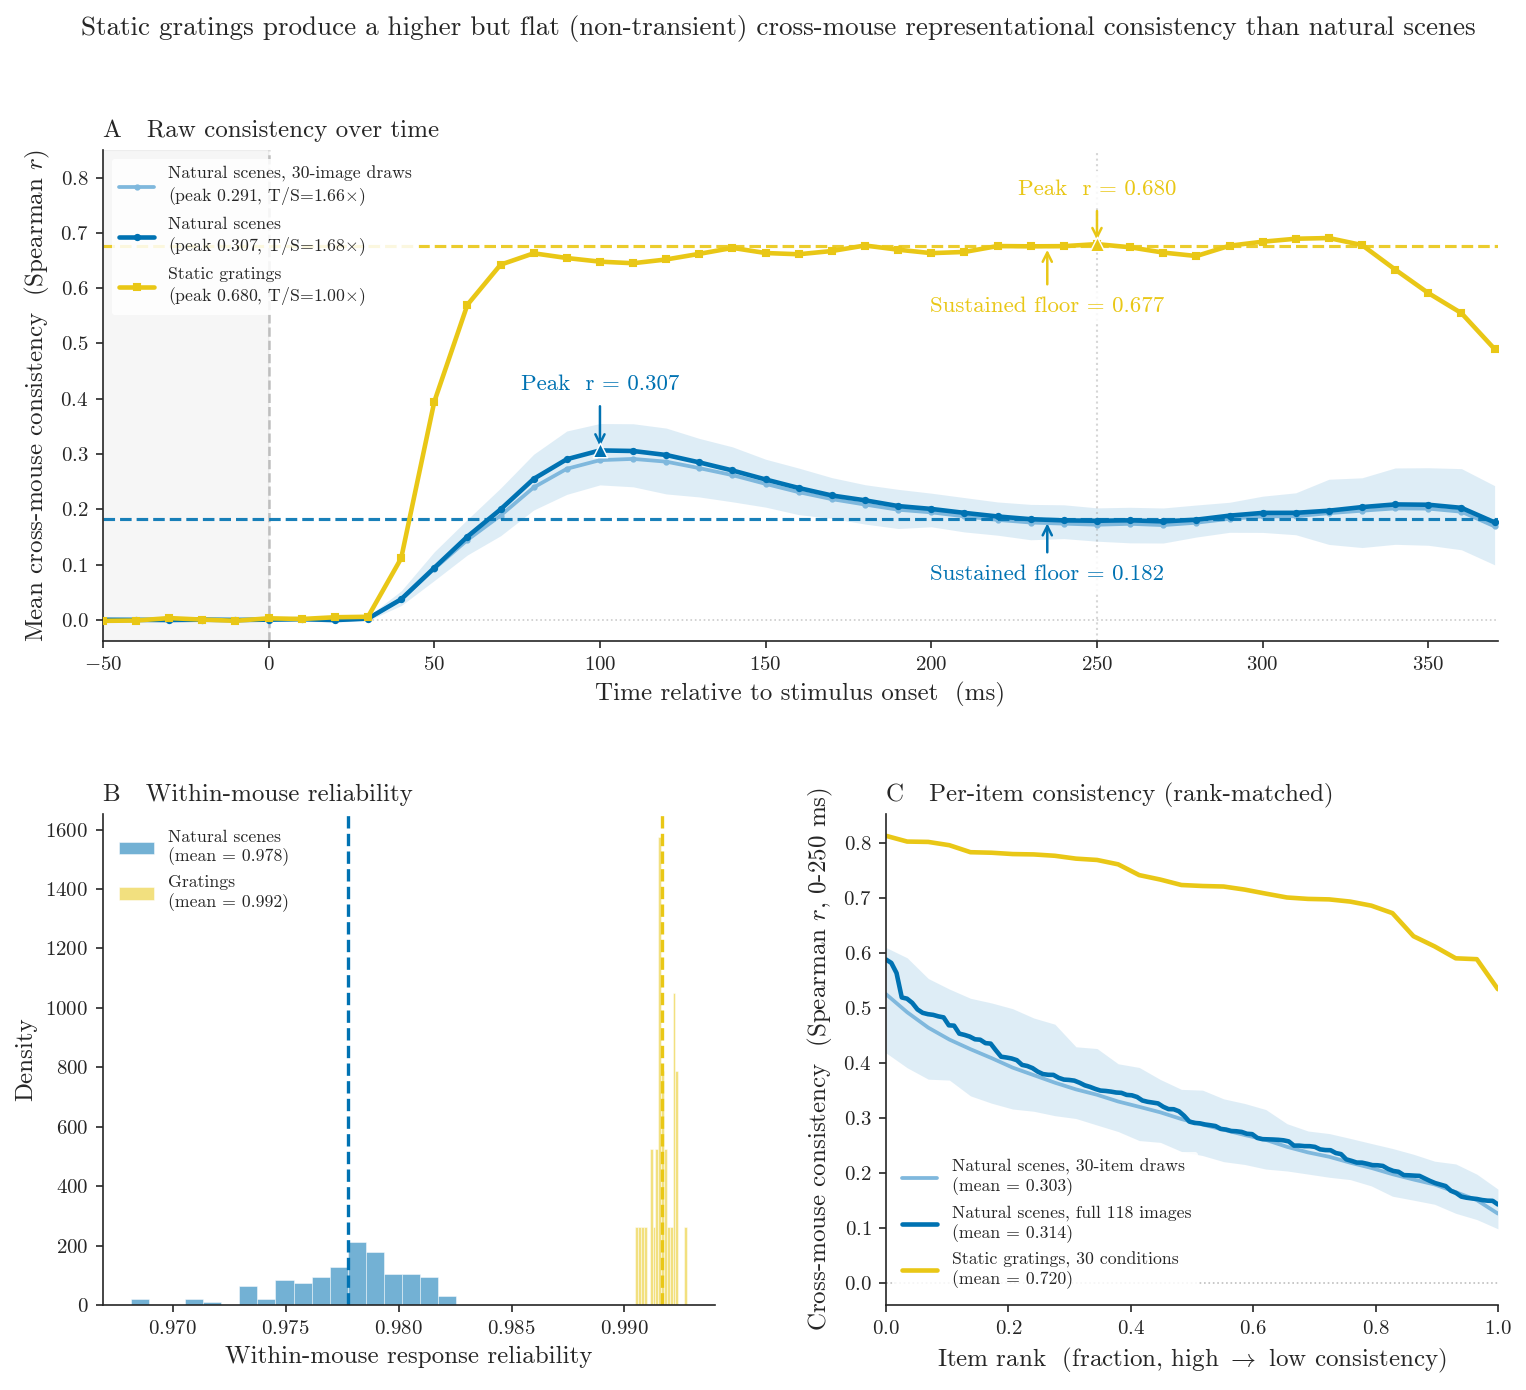

In [11]:
fig = plt.figure(figsize=(12, 10))
gs  = fig.add_gridspec(2, 2, height_ratios=[1, 1], hspace=0.35, wspace=0.28)
ax        = fig.add_subplot(gs[0, :])
ax_hist   = fig.add_subplot(gs[1, 0])
ax_sorted = fig.add_subplot(gs[1, 1])

text_bbox = dict(facecolor='white', alpha=0.85, edgecolor='none')

# ── Panel A: sliding-window temporal profiles (top, full width) ─────────────
def setup_time_ax(ax):
    ax.axvspan(SLIDE_START_MS, 0, color='gray', alpha=0.07)
    ax.axvline(0,   color=COL_REF, linestyle='--', linewidth=1.2, alpha=0.6)
    ax.axvline(250, color=COL_REF, linestyle=':',  linewidth=1.0, alpha=0.4)
    ax.axhline(0,   color='gray',  linestyle=':',  linewidth=0.8, alpha=0.4)
    ax.set_xlabel('Time relative to stimulus onset  (ms)')
    ax.xaxis.set_major_locator(mticker.MultipleLocator(50))
    ax.set_xlim(SLIDE_START_MS, SLIDE_END_MS)
    ax.spines[['top', 'right']].set_visible(False)


def mark_peak_floor(ax, t, c, peak, sus, color, peak_off, floor_off,
                    floor_x=235):
    t = np.asarray(t)
    c = np.asarray(c)
    post_mask = (t >= 0) & (t <= 250)
    if np.any(post_mask):
        peak_t = t[post_mask][np.argmax(c[post_mask])]
    else:
        peak_t = t[np.argmax(c)]

    ax.scatter([peak_t], [peak], marker='^', s=48, color=color, zorder=6,
               edgecolor='white', linewidth=0.7)
    ax.annotate(f'Peak  r = {peak:.3f}',
                xy=(peak_t, peak),
                xytext=(peak_t + peak_off[0], peak + peak_off[1]),
                arrowprops=dict(arrowstyle='->', color=color, lw=1.2),
                fontsize=11, color=color, ha='center', va='center', bbox=text_bbox)

    ax.hlines(sus, SLIDE_START_MS, SLIDE_END_MS,
              colors=color, linewidth=1.5, linestyle='--', alpha=0.9)

    ax.annotate(f'Sustained floor = {sus:.3f}',
                xy=(floor_x, sus),
                xytext=(floor_x + floor_off[0], sus + floor_off[1]),
                arrowprops=dict(arrowstyle='->', color=color, lw=1.2),
                fontsize=11, color=color, ha='center', va='center', bbox=text_bbox)

setup_time_ax(ax)

# Item-count-matched control (natural scenes subsampled to 30 images/draw,
# matching the gratings condition count)
ax.fill_between(times_ms_ns_sub, ci_lo_ns_sub, ci_hi_ns_sub,
                 color=COL_SUB, alpha=0.25, linewidth=0)
ax.plot(times_ms_ns_sub, mean_c_ns_sub, color=COL_SUB, linewidth=1.8,
        marker='o', markersize=2, zorder=2,
        label=f'Natural scenes, 30-image draws\n('
              f'peak {peak_c_ns_sub:.3f}, T/S={ts_ratio_ns_sub:.2f}$\\times$)')

ax.plot(times_ms_ns, mean_c_ns, color=COL_DATA, linewidth=2.2,
        marker='o', markersize=2.5, zorder=4,
        label=f'Natural scenes\n(peak {peak_c_ns:.3f}, T/S={ts_ratio_ns:.2f}$\\times$)')
ax.plot(times_ms_gr, mean_c_gr, color=COL_GR, linewidth=2.2,
        marker='s', markersize=2.5, zorder=4,
        label=f'Static gratings\n(peak {peak_c_gr:.3f}, T/S={ts_ratio_gr:.2f}$\\times$)')

mark_peak_floor(ax, times_ms_ns, mean_c_ns, peak_c_ns, sust_ns, COL_DATA,
                peak_off=(0, 0.12), floor_off=(0, -0.10))
mark_peak_floor(ax, times_ms_gr, mean_c_gr, peak_c_gr, sust_gr, COL_GR,
                peak_off=(0, 0.10), floor_off=(0, -0.11))
ax.set_ylim(top=0.85)

ax.set_ylabel('Mean cross-mouse consistency  (Spearman $r$)')
ax.set_title('A   Raw consistency over time', loc='left', fontweight='bold', pad=6)
ax.legend(frameon=True, facecolor='white', edgecolor='none', framealpha=0.85, fontsize=8.5)

# ── Panel B: within-mouse reliability, natural scenes vs. gratings ───────────
ax_hist.hist(reliability_ns, bins=18, color=COL_DATA, alpha=0.55, density=True,
             edgecolor='white', linewidth=0.4,
             label=f'Natural scenes\n(mean = {reliability_ns.mean():.3f})')
ax_hist.hist(mean_nc_gr, bins=18, color=COL_GR, alpha=0.55, density=True,
             edgecolor='white', linewidth=0.4,
             label=f'Gratings\n(mean = {mean_nc_gr.mean():.3f})')
ax_hist.axvline(reliability_ns.mean(), color=COL_DATA, linestyle='--', linewidth=1.6)
ax_hist.axvline(mean_nc_gr.mean(), color=COL_GR, linestyle='--', linewidth=1.6)
ax_hist.set_xlabel('Within-mouse response reliability')
ax_hist.set_ylabel('Density')
ax_hist.set_title('B   Within-mouse reliability', loc='left', fontweight='bold', pad=6)
ax_hist.legend(frameon=True, facecolor='white', edgecolor='none', framealpha=0.85, fontsize=8.5, loc='upper left')
ax_hist.spines[['top', 'right']].set_visible(False)

# ── Panel C: sorted per-item consistency, rank-fraction x-axis ──────────────
sorted_ns = np.sort(consistency_ns_full)[::-1]
sorted_gr = np.sort(c_gr_per_cond)[::-1]
rank_frac_ns  = np.arange(len(sorted_ns)) / (len(sorted_ns) - 1)
rank_frac_gr  = np.arange(len(sorted_gr)) / (len(sorted_gr) - 1)
rank_frac_sub = np.arange(N_CONDITIONS) / (N_CONDITIONS - 1)

ax_sorted.fill_between(rank_frac_sub, c_ns_sub_sorted_lo, c_ns_sub_sorted_hi,
                        color=COL_SUB, alpha=0.25, linewidth=0)
ax_sorted.plot(rank_frac_sub, c_ns_sub_sorted_mean, color=COL_SUB, linewidth=1.8,
               label=f'Natural scenes, 30-item draws\n('
                     f'mean = {c_ns_sub_sorted_mean.mean():.3f})')
ax_sorted.plot(rank_frac_ns, sorted_ns, color=COL_DATA, linewidth=2.2,
               label=f'Natural scenes, full 118 images\n(mean = {sorted_ns.mean():.3f})')
ax_sorted.plot(rank_frac_gr, sorted_gr, color=COL_GR, linewidth=2.2,
               label=f'Static gratings, 30 conditions\n(mean = {sorted_gr.mean():.3f})')
ax_sorted.axhline(0, color='gray', linestyle=':', linewidth=0.8, alpha=0.5)
ax_sorted.set_xlabel(r'Item rank  (fraction, high $\rightarrow$ low consistency)')
ax_sorted.set_ylabel('Cross-mouse consistency  (Spearman $r$, 0-250 ms)')
ax_sorted.set_xlim(0, 1)
ax_sorted.set_title('C   Per-item consistency (rank-matched)', loc='left',
                     fontweight='bold', pad=6)
ax_sorted.legend(frameon=True, facecolor='white', edgecolor='none', framealpha=0.85, fontsize=8.5)
ax_sorted.spines[['top', 'right']].set_visible(False)

fig.suptitle('Static gratings produce a higher but flat (non-transient) '
             'cross-mouse representational consistency than natural scenes',
             y=0.97)

print_figure_data(
    'Fig. 6A — raw consistency over time: natural scenes vs. static gratings',
    times_ms_natural_scenes=times_ms_ns,
    mean_consistency_natural_scenes=mean_c_ns,
    times_ms_gratings=times_ms_gr,
    mean_consistency_gratings=mean_c_gr,
    times_ms_natural_scenes_item_matched=times_ms_ns_sub,
    mean_consistency_natural_scenes_item_matched=mean_c_ns_sub,
    ci_lo_natural_scenes_item_matched=ci_lo_ns_sub,
    ci_hi_natural_scenes_item_matched=ci_hi_ns_sub,
    peak_consistency_natural_scenes=peak_c_ns,
    peak_time_ms_natural_scenes=peak_t_ns,
    peak_consistency_gratings=peak_c_gr,
    peak_time_ms_gratings=peak_t_gr,
    peak_consistency_natural_scenes_item_matched=peak_c_ns_sub,
    peak_time_ms_natural_scenes_item_matched=peak_t_ns_sub,
    ts_ratio_natural_scenes=ts_ratio_ns,
    ts_ratio_gratings=ts_ratio_gr,
    ts_ratio_natural_scenes_item_matched=ts_ratio_ns_sub,
    within_mouse_reliability_natural_scenes=mean_nc_ns,
    within_mouse_reliability_gratings=scalar_nc_gr,
)
print_figure_data(
    'Fig. 6B — within-mouse reliability: natural scenes vs. gratings',
    reliability_natural_scenes=reliability_ns,
    reliability_gratings=mean_nc_gr,
)
print_figure_data(
    'Fig. 6C — sorted per-item consistency (rank-matched): natural scenes vs. gratings',
    rank_fraction_natural_scenes=rank_frac_ns,
    consistency_natural_scenes_sorted=sorted_ns,
    rank_fraction_gratings=rank_frac_gr,
    consistency_gratings_sorted=sorted_gr,
    rank_fraction_natural_scenes_item_matched=rank_frac_sub,
    consistency_natural_scenes_item_matched_sorted_mean=c_ns_sub_sorted_mean,
    consistency_natural_scenes_item_matched_sorted_lo=c_ns_sub_sorted_lo,
    consistency_natural_scenes_item_matched_sorted_hi=c_ns_sub_sorted_hi,
)

plt.savefig(FIGURES_DIR / 'fig6_gratings_vs_natural_scenes.png', bbox_inches='tight')
plt.show()